<a target="_blank" href="https://colab.research.google.com/github/ares2012/temp/blob/master/Open_in_Colab.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

https://openincolab.com

---


https://colab.research.google.com/github/ares2012/temp/blob/master/New_notebook.ipynb

https://colab.research.google.com/github/ares2012/temp/blob/master/run_experiment.ipynb
https://colab.research.google.com/github/ares2012/temp/blob/master/cds_experiment.ipynb

In [1]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 2 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 2s (5,588 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 117540 files and direc

# 세션 다시 시작

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import json

import numpy as np
import pandas as pd

In [ ]:
cp -r /content/drive/MyDrive/Colab\ Notebooks/my_list.txt /content

In [ ]:
import json
file_path = '/content/my_list.txt'
file_path = '/content/drive/MyDrive/ColabNotebooks/env/my_list.txt'

In [ ]:
with open(file_path, 'r') as f:
  keys = json.load(f)

oKEY = keys['OPENAI_API_KEY']
pKEY = keys['PINECONE_API_KEY']
hKEY = keys['huggingface.co']

In [ ]:
!pip install openai --upgrade --quiet

# EDA: result_data CSV 파일 분석

이 노트북은 `result_data` 디렉토리에 있는 18개의 CSV 파일(5개 LLM 모델 × 3개 데이터셋)을 분석합니다.

## 목표
- 모델별 성능 비교 (gemma-3-4b-it, Llama-3.2-3B-Instruct, Phi-3-mini-128k-instruct, Phi-3.5-mini-instruct, Phi-4-mini-instruct, Qwen3-4B-Instruct-2507)
- 데이터셋별 패턴 분석 (hotpot_qa, ms_marco, squad)
- 핵심 메트릭 시각화 및 상관관계 분석


## 1. Setup: 라이브러리 및 환경 설정

In [2]:
# 필수 라이브러리 임포트
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path
import warnings

# 경고 메시지 무시
warnings.filterwarnings('ignore')

# 시각화 설정
sns.set_style("whitegrid")
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# 한글 폰트 설정 (Windows)
#plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

print("라이브러리 로드 완료!")

라이브러리 로드 완료!


## 2. 데이터 로드 및 통합

In [3]:
# result_data 디렉토리 경로 설정
data_dir = Path(r'/content/drive/MyDrive/ColabNotebooks/results/CDS_4B')

# CSV 파일 목록 가져오기
csv_files = sorted(data_dir.glob('*.csv'))

print(f"발견된 CSV 파일 개수: {len(csv_files)}")
print("\n파일 목록:")
for f in csv_files:
    print(f"  - {f.name}")

발견된 CSV 파일 개수: 18

파일 목록:
  - Llama-3.2-3B-Instruct_hotpot_qa.csv
  - Llama-3.2-3B-Instruct_ms_marco.csv
  - Llama-3.2-3B-Instruct_squad.csv
  - Phi-3-mini-128k-instruct_hotpot_qa.csv
  - Phi-3-mini-128k-instruct_ms_marco.csv
  - Phi-3-mini-128k-instruct_squad.csv
  - Phi-3.5-mini-instruct_hotpot_qa.csv
  - Phi-3.5-mini-instruct_ms_marco.csv
  - Phi-3.5-mini-instruct_squad.csv
  - Phi-4-mini-instruct_hotpot_qa.csv
  - Phi-4-mini-instruct_ms_marco.csv
  - Phi-4-mini-instruct_squad.csv
  - Qwen3-4B-Instruct-2507_hotpot_qa.csv
  - Qwen3-4B-Instruct-2507_ms_marco.csv
  - Qwen3-4B-Instruct-2507_squad.csv
  - gemma-3-4b-it_hotpot_qa.csv
  - gemma-3-4b-it_ms_marco.csv
  - gemma-3-4b-it_squad.csv


In [ ]:
df = pd.read_csv(csv_files[0])
df.isnull().sum(), df.describe()
df[df.isnull().any(axis=1)], csv_files[0]

In [ ]:
df = pd.read_csv(csv_files[0])
df.isnull().sum(), df.describe()
df[df.isnull().any(axis=1)], csv_files[1]

In [ ]:
df = pd.read_csv(csv_files[0])
df.isnull().sum(), df.describe()
df[df.isnull().any(axis=1)], csv_files[2]

In [ ]:
df = pd.read_csv(csv_files[0])
df.isnull().sum(), df.describe()
df[df.isnull().any(axis=1)], csv_files[9]

In [4]:
# 모든 CSV 파일을 로드하고 모델명과 데이터셋명 파싱
data_list = []

for csv_file in csv_files[:-3]:
    # 파일명에서 모델명과 데이터셋명 추출
    filename = csv_file.stem  # 확장자 제외
    parts = filename.rsplit('_', 2)  # 마지막 '_'로 분리

    model_name = parts[0]
    if len(parts) >= 3:
        dataset_name = '_'.join(parts[1:])
    else:
        dataset_name = parts[-1]

    # CSV 파일 로드
    df = pd.read_csv(csv_file)
    df['model'] = model_name
    df['dataset'] = dataset_name
    df['filename'] = csv_file.name

    data_list.append(df)

# 모든 데이터 통합
df_all = pd.concat(data_list, ignore_index=True)

print(f"통합 데이터셋 크기: {df_all.shape}")
print(f"\n고유 모델 수: {df_all['model'].nunique()}")
print(f"고유 데이터셋 수: {df_all['dataset'].nunique()}")
print(f"\n모델 목록:\n{df_all['model'].unique()}")
print(f"\n데이터셋 목록:\n{df_all['dataset'].unique()}")

통합 데이터셋 크기: (3000, 13)

고유 모델 수: 5
고유 데이터셋 수: 3

모델 목록:
['Llama-3.2-3B-Instruct' 'Phi-3-mini-128k-instruct'
 'Phi-3.5-mini-instruct' 'Phi-4-mini-instruct' 'Qwen3-4B-Instruct-2507']

데이터셋 목록:
['hotpot_qa' 'ms_marco' 'squad']


## 3. 데이터 품질 검증

In [5]:
# 데이터 미리보기
print("=== 데이터 샘플 ===")
display(df_all.head(10))

print("\n=== 데이터 정보 ===")
print(df_all.info())

print("\n=== 컬럼 목록 ===")
print(df_all.columns.tolist())

=== 데이터 샘플 ===


,id,cds_faithful,cds_distracted,cds_diff,len_faithful,len_distracted,len_diff,context_drop,question_rise,total_shift,model,dataset,filename
0,0,0.567375,0.708491,-0.141116,4817,3656,1161,-41.152845,-3.863448,-45.016293,Llama-3.2-3B-Instruct,hotpot_qa,Llama-3.2-3B-Instruct_hotpot_qa.csv
1,1,0.755373,0.631135,0.124239,8758,5643,3115,29.849197,10.726114,40.575311,Llama-3.2-3B-Instruct,hotpot_qa,Llama-3.2-3B-Instruct_hotpot_qa.csv
2,2,0.614520,0.520727,0.093793,4898,3227,1671,39.257627,-4.474554,34.783074,Llama-3.2-3B-Instruct,hotpot_qa,Llama-3.2-3B-Instruct_hotpot_qa.csv
3,3,0.771763,0.718425,0.053339,6095,5282,813,0.493980,6.077333,6.571313,Llama-3.2-3B-Instruct,hotpot_qa,Llama-3.2-3B-Instruct_hotpot_qa.csv
4,4,0.774981,0.686225,0.088756,4343,4676,-333,-5.750570,13.717473,7.966903,Llama-3.2-3B-Instruct,hotpot_qa,Llama-3.2-3B-Instruct_hotpot_qa.csv
5,5,0.496062,0.597324,-0.101262,4443,4335,108,26.027082,-40.019690,-13.992609,Llama-3.2-3B-Instruct,hotpot_qa,Llama-3.2-3B-Instruct_hotpot_qa.csv
6,6,0.782308,0.760553,0.021755,6151,9655,-3504,-14.699172,9.049414,-5.649758,Llama-3.2-3B-Instruct,hotpot_qa,Llama-3.2-3B-Instruct_hotpot_qa.csv
7,7,0.714443,0.845113,-0.130670,5076,6447,-1371,-98.327250,-4.663536,-102.990786,Llama-3.2-3B-Instruct,hotpot_qa,Llama-3.2-3B-Instruct_hotpot_qa.csv
8,8,0.591328,0.619499,-0.028171,4746,4580,166,4.834391,-10.198466,-5.364075,Llama-3.2-3B-Instruct,hotpot_qa,Llama-3.2-3B-Instruct_hotpot_qa.csv
9,9,0.807672,0.637297,0.170375,5846,4199,1647,96.716314,-7.974593,88.741721,Llama-3.2-3B-Instruct,hotpot_qa,Llama-3.2-3B-Instruct_hotpot_qa.csv



=== 데이터 정보 ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              3000 non-null   int64  
 1   cds_faithful    2999 non-null   float64
 2   cds_distracted  2999 non-null   float64
 3   cds_diff        2998 non-null   float64
 4   len_faithful    3000 non-null   int64  
 5   len_distracted  3000 non-null   int64  
 6   len_diff        3000 non-null   int64  
 7   context_drop    3000 non-null   float64
 8   question_rise   3000 non-null   float64
 9   total_shift     3000 non-null   float64
 10  model           3000 non-null   object 
 11  dataset         3000 non-null   object 
 12  filename        3000 non-null   object 
dtypes: float64(6), int64(4), object(3)
memory usage: 304.8+ KB
None

=== 컬럼 목록 ===
['id', 'cds_faithful', 'cds_distracted', 'cds_diff', 'len_faithful', 'len_distracted', 'len_diff', 'context_drop', 'qu

=== 결측치 개수 ===


,결측치 개수,결측치 비율(%)
cds_faithful,1,0.033333
cds_distracted,1,0.033333
cds_diff,2,0.066667


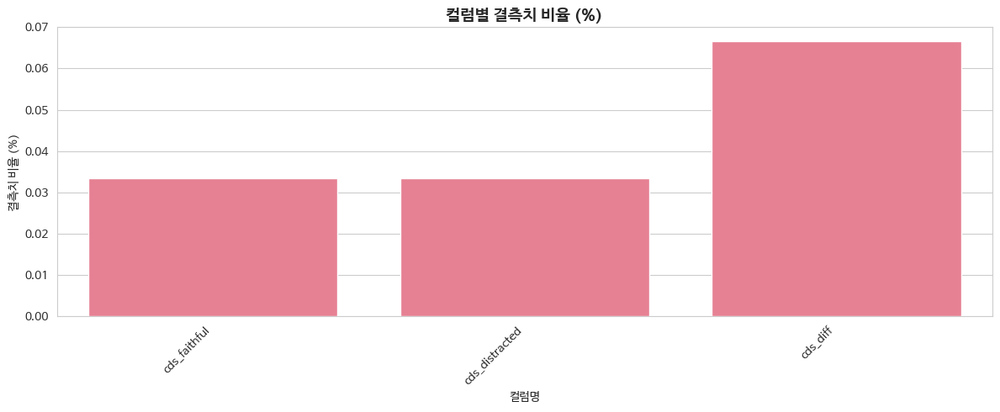

In [6]:
# 결측치 확인
print("=== 결측치 개수 ===")
missing_values = df_all.isnull().sum()
missing_percent = (missing_values / len(df_all)) * 100
missing_df = pd.DataFrame({
    '결측치 개수': missing_values,
    '결측치 비율(%)': missing_percent
})
display(missing_df[missing_df['결측치 개수'] > 0])

# 결측치 시각화
plt.figure(figsize=(12, 5))
missing_cols = missing_df[missing_df['결측치 개수'] > 0].index
if len(missing_cols) > 0:
    sns.barplot(x=missing_cols, y=missing_df.loc[missing_cols, '결측치 비율(%)'])
    plt.title('컬럼별 결측치 비율 (%)', fontsize=14, fontweight='bold')
    plt.xlabel('컬럼명')
    plt.ylabel('결측치 비율 (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("\n결측치가 없습니다!")

In [7]:
# 기본 통계량 확인
print("=== 수치형 컬럼 기본 통계량 ===")
numeric_cols = df_all.select_dtypes(include=[np.number]).columns
display(df_all[numeric_cols].describe())

=== 수치형 컬럼 기본 통계량 ===


,id,cds_faithful,cds_distracted,cds_diff,len_faithful,len_distracted,len_diff,context_drop,question_rise,total_shift
count,3000.00000,2999.000000,2999.000000,2998.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,99.50000,0.710223,0.675572,0.034692,3135.215000,3152.602000,-17.387000,NaN,8.470577,NaN
std,57.74393,0.156473,0.163446,0.142965,2157.138433,2186.657073,1548.000666,NaN,55.718091,NaN
min,0.00000,0.012556,0.033591,-0.791550,157.000000,157.000000,-7333.000000,-inf,-468.059950,-inf
25%,49.75000,0.612863,0.559672,-0.031034,874.250000,888.750000,-534.500000,-38.875680,-6.384229,-25.320267
50%,99.50000,0.721058,0.673634,0.033872,2966.000000,2963.000000,-16.000000,2.365501,3.466300,3.944842
75%,149.25000,0.829265,0.798706,0.105188,4766.250000,4766.000000,512.000000,32.890844,16.865106,37.071342
max,199.00000,0.993904,0.994296,0.764919,10669.000000,10669.000000,6782.000000,inf,1383.595344,inf


## 4. 모델별 성능 비교

In [8]:
# 모델별 주요 메트릭 평균값 계산
key_metrics = ['cds_faithful', 'cds_distracted', 'cds_diff', 'len_diff', 'total_shift']

model_stats = df_all.groupby('model')[key_metrics].agg(['mean', 'median', 'std']).round(4)
print("=== 모델별 주요 메트릭 통계 ===")
display(model_stats)

=== 모델별 주요 메트릭 통계 ===


cds_faithful                 cds_distracted          \
                                 mean  median     std           mean  median   
model                                                                          
Llama-3.2-3B-Instruct          0.5971  0.6010  0.1343         0.5875  0.5953   
Phi-3-mini-128k-instruct       0.7756  0.7903  0.1114         0.7141  0.7335   
Phi-3.5-mini-instruct          0.7009  0.7023  0.1213         0.6455  0.6455   
Phi-4-mini-instruct            0.8616  0.8929  0.1030         0.8485  0.8896   
Qwen3-4B-Instruct-2507         0.6159  0.6080  0.1332         0.5823  0.5657   

                                 cds_diff                 len_diff         \
                             std     mean  median     std     mean median   
model                                                                       
Llama-3.2-3B-Instruct     0.1393   0.0096  0.0090  0.1353 -24.3267  -16.5   
Phi-3-mini-128k-instruct  0.1322   0.0615  0.0612  0.1263 -36.4950   -4.5   
Phi-3.5-mini-instruct     0.1160   0.0556  0.0559  0.1617  40.8250   18.5   
Phi-4-mini-instruct       0.1137   0.0131  0.0088  0.1190 -49.8700  -55.0   
Qwen3-4B-Instruct-2507    0.1471   0.0337  0.0414  0.1598 -17.0683  -15.0   

                                    total_shift                     
                                std        mean   median       std  
model                                                               
Llama-3.2-3B-Instruct     1659.2960     -0.0952   0.2519   52.4142  
Phi-3-mini-128k-instruct  1521.2107      8.2823   8.5667  254.8160  
Phi-3.5-mini-instruct     1480.8159         NaN   0.4525       NaN  
Phi-4-mini-instruct       1537.3088     16.0627  24.2863  392.4462  
Qwen3-4B-Instruct-2507    1539.2166      4.2389   3.4609   93.4725

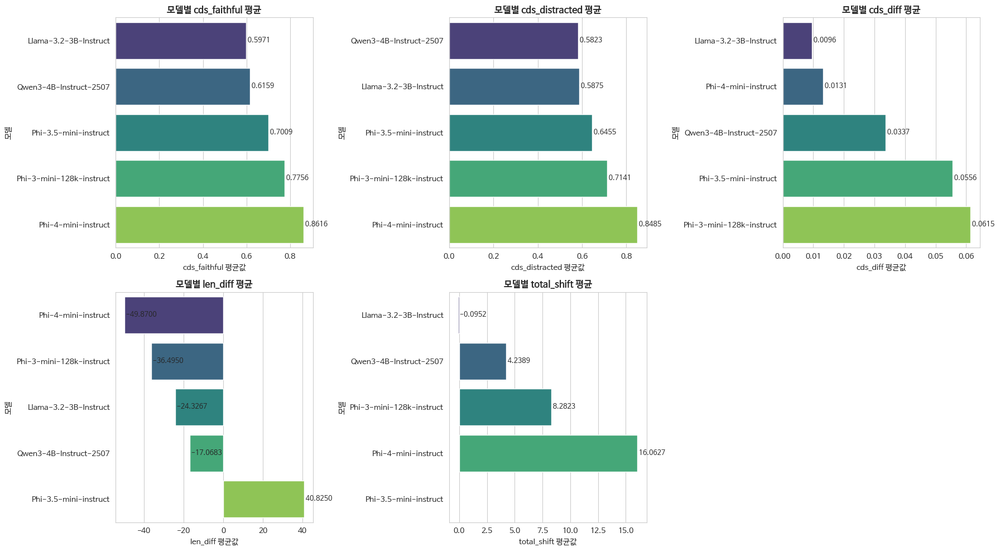

In [9]:
# 모델별 성능 비교: Bar Plot
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, metric in enumerate(key_metrics):
    ax = axes[idx]
    model_means = df_all.groupby('model')[metric].mean().sort_values()

    sns.barplot(x=model_means.values, y=model_means.index, ax=ax, palette='viridis')
    ax.set_title(f'모델별 {metric} 평균', fontsize=12, fontweight='bold')
    ax.set_xlabel(f'{metric} 평균값')
    ax.set_ylabel('모델')

    # 값 표시
    for i, v in enumerate(model_means.values):
        ax.text(v, i, f' {v:.4f}', va='center', fontsize=9)

# 남은 subplot 제거
if len(key_metrics) < 6:
    fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

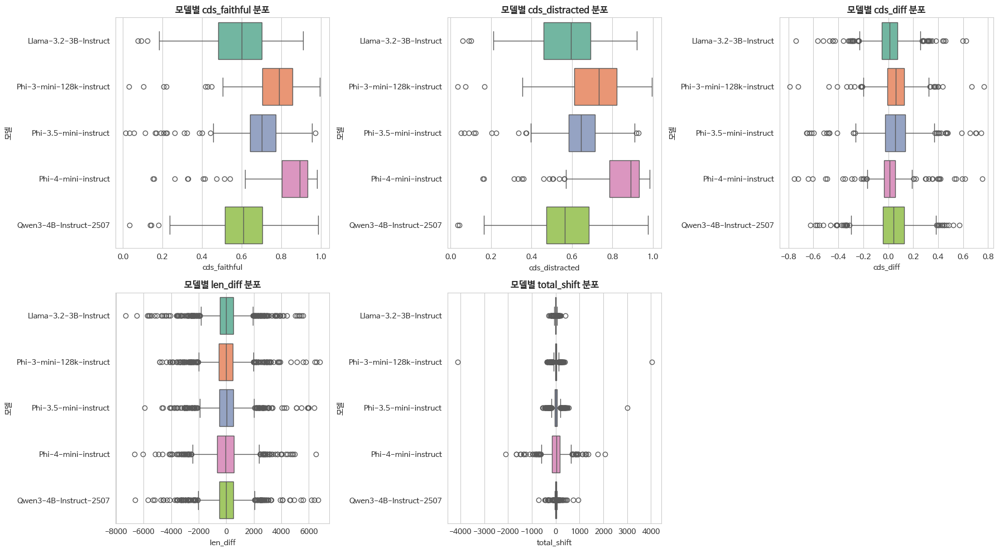

In [10]:
# 모델별 성능 분포: Box Plot
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, metric in enumerate(key_metrics):
    ax = axes[idx]
    sns.boxplot(data=df_all, y='model', x=metric, ax=ax, palette='Set2')
    ax.set_title(f'모델별 {metric} 분포', fontsize=12, fontweight='bold')
    ax.set_xlabel(metric)
    ax.set_ylabel('모델')

# 남은 subplot 제거
if len(key_metrics) < 6:
    fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

## 5. 데이터셋별 패턴 분석

In [11]:
# 데이터셋별 주요 메트릭 평균값 계산
dataset_stats = df_all.groupby('dataset')[key_metrics].agg(['mean', 'median', 'std']).round(4)
print("=== 데이터셋별 주요 메트릭 통계 ===")
display(dataset_stats)

=== 데이터셋별 주요 메트릭 통계 ===


cds_faithful                 cds_distracted                  \
                  mean  median     std           mean  median     std   
dataset                                                                 
hotpot_qa       0.7771  0.7823  0.1279         0.7552  0.7603  0.1398   
ms_marco        0.7328  0.7492  0.1647         0.7046  0.7028  0.1597   
squad           0.6208  0.6310  0.1305         0.5670  0.5436  0.1271   

          cds_diff                 len_diff                   total_shift  \
              mean  median     std     mean median        std        mean   
dataset                                                                     
hotpot_qa   0.0220  0.0119  0.1382  -42.437  -15.0  2280.3764         NaN   
ms_marco    0.0282  0.0307  0.1841   -2.602  -10.0  1334.0880      2.2157   
squad       0.0538  0.0486  0.0884   -7.122  -17.0   461.3629      7.6705   

                             
           median       std  
dataset                      
hotpot_qa  6.1378       NaN  
ms_marco   1.8656  252.3409  
squad      4.2535   63.3926

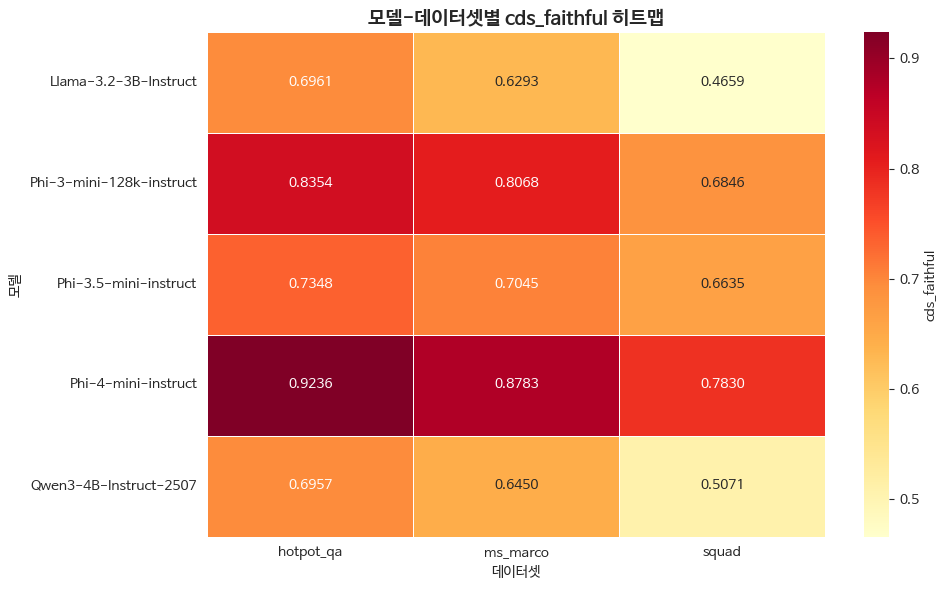

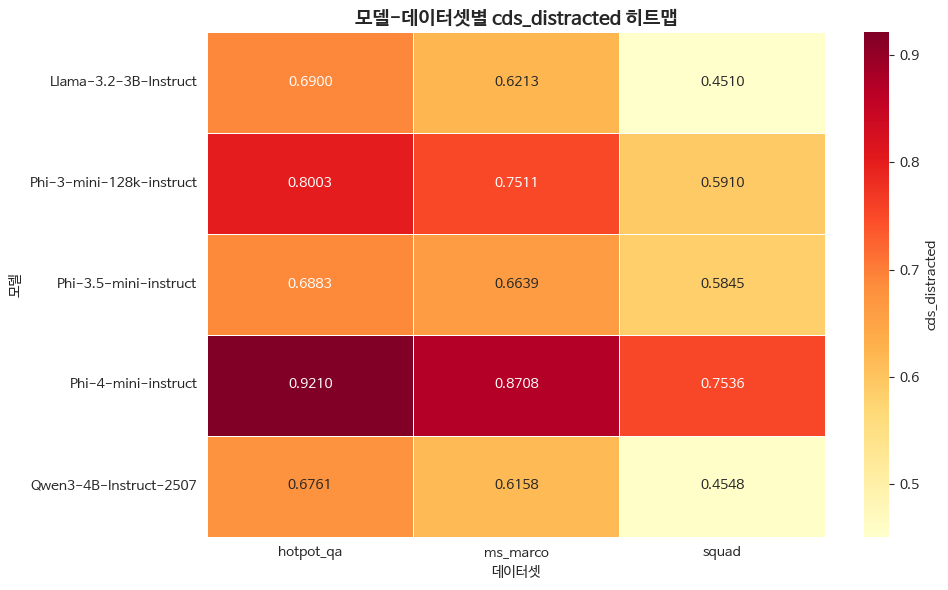

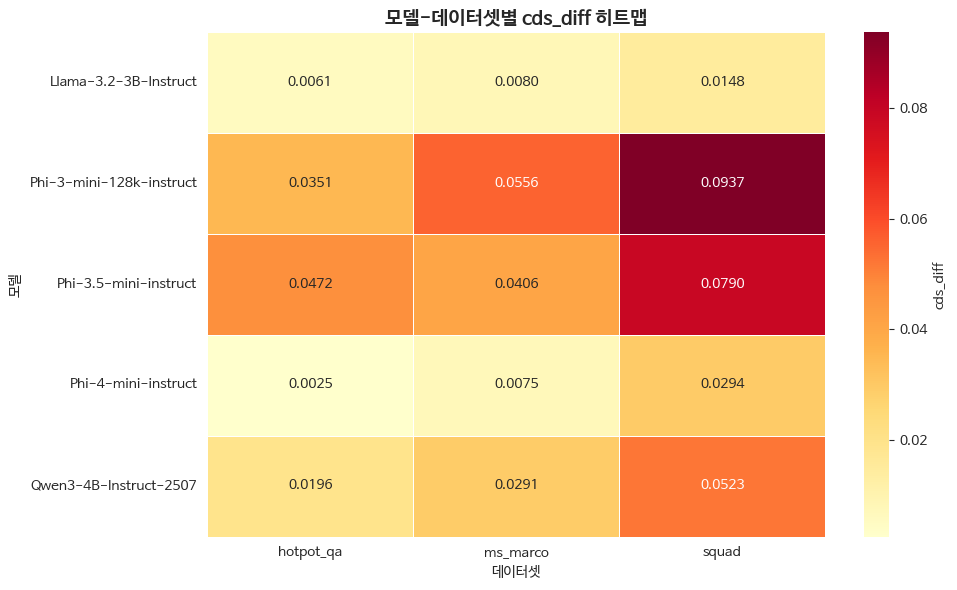

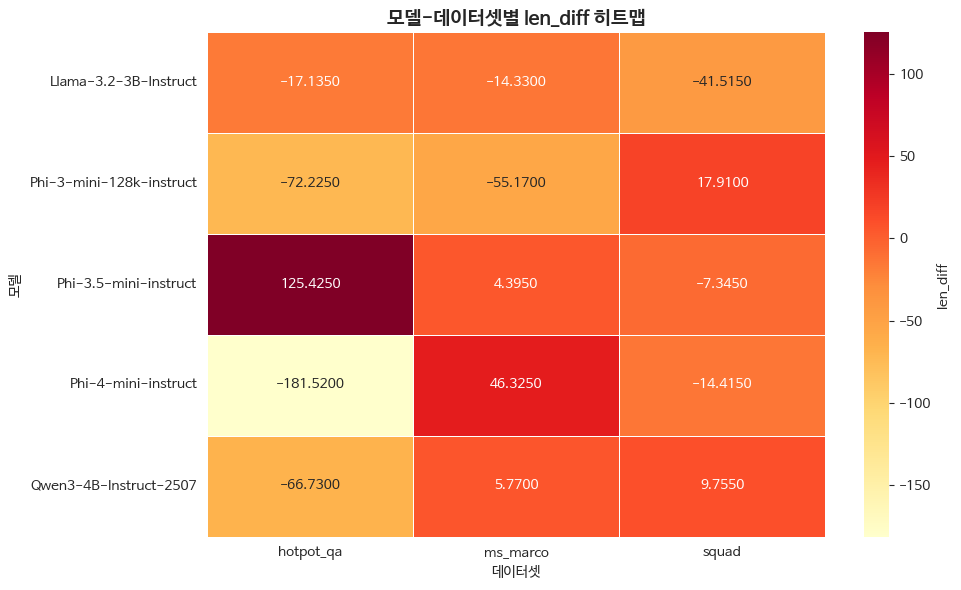

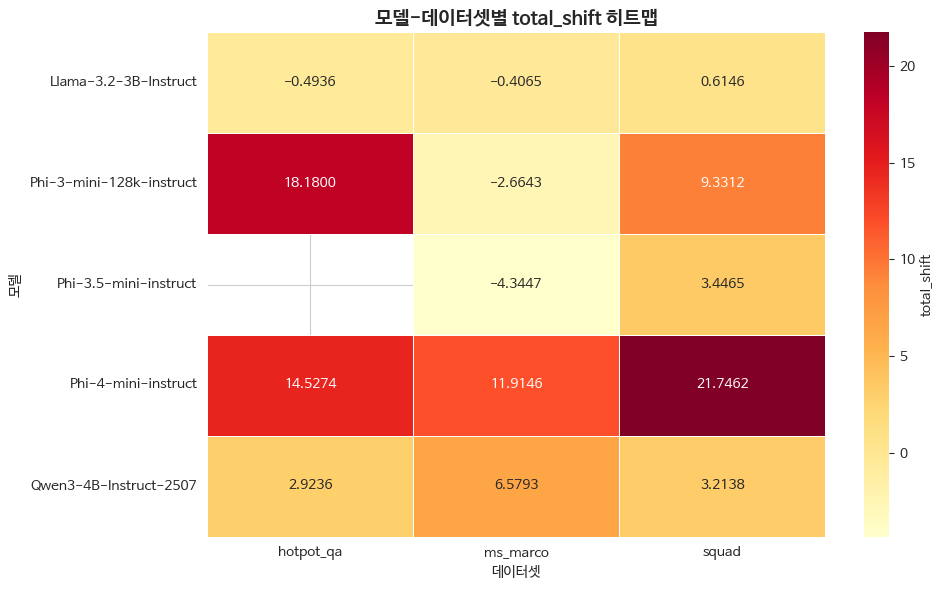

In [12]:
# 모델-데이터셋 조합별 성능 히트맵
for metric in key_metrics:
    plt.figure(figsize=(10, 6))

    # 피벗 테이블 생성
    pivot_data = df_all.pivot_table(values=metric, index='model', columns='dataset', aggfunc='mean')

    # 히트맵 그리기
    sns.heatmap(pivot_data, annot=True, fmt='.4f', cmap='YlOrRd', linewidths=0.5, cbar_kws={'label': metric})
    plt.title(f'모델-데이터셋별 {metric} 히트맵', fontsize=14, fontweight='bold')
    plt.xlabel('데이터셋')
    plt.ylabel('모델')
    plt.tight_layout()
    plt.show()

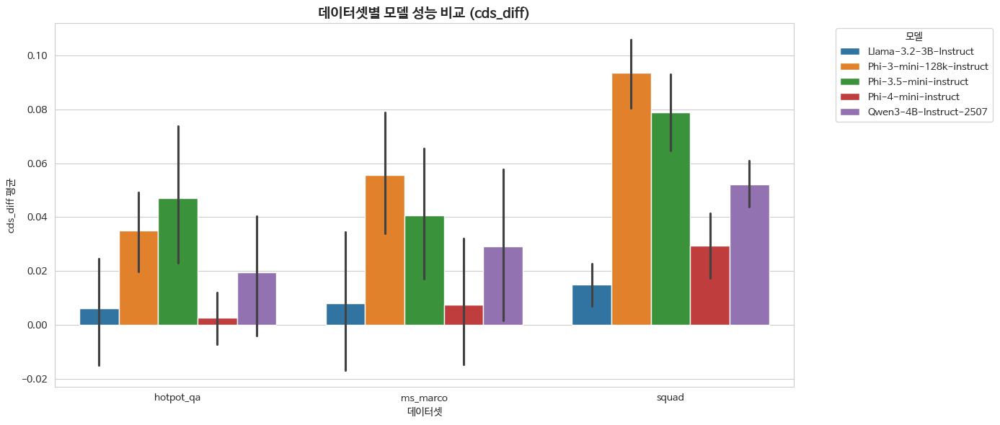

In [13]:
# 데이터셋별 모델 성능 비교 (cds_diff 기준)
plt.figure(figsize=(14, 6))
sns.barplot(data=df_all, x='dataset', y='cds_diff', hue='model', palette='tab10')
plt.title('데이터셋별 모델 성능 비교 (cds_diff)', fontsize=14, fontweight='bold')
plt.xlabel('데이터셋')
plt.ylabel('cds_diff 평균')
plt.legend(title='모델', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 6. 상관관계 분석

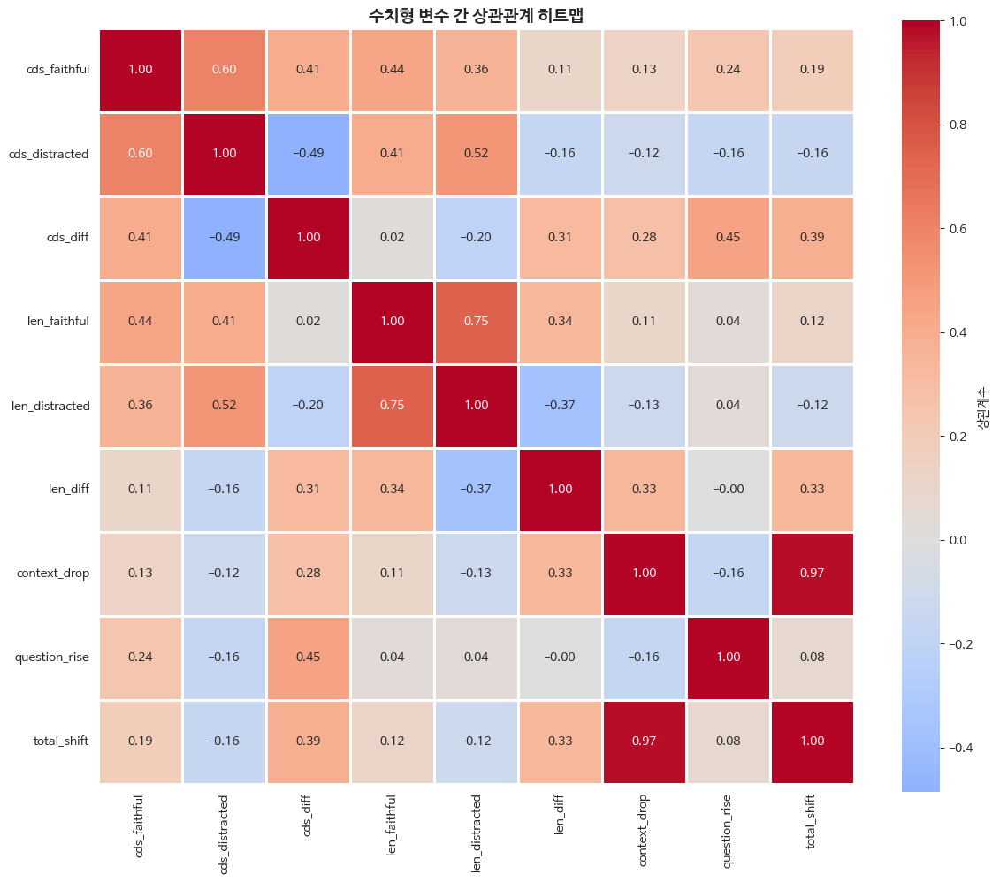


=== 상관계수가 높은 변수 쌍 (|r| > 0.7) ===


,변수1,변수2,상관계수
1,context_drop,total_shift,0.971311
0,len_faithful,len_distracted,0.746081


In [14]:
# 수치형 컬럼만 선택
numeric_cols_for_corr = ['cds_faithful', 'cds_distracted', 'cds_diff',
                         'len_faithful', 'len_distracted', 'len_diff',
                         'context_drop', 'question_rise', 'total_shift']

# 상관계수 행렬 계산
correlation_matrix = df_all[numeric_cols_for_corr].corr()

# 상관관계 히트맵
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=1, cbar_kws={'label': '상관계수'})
plt.title('수치형 변수 간 상관관계 히트맵', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n=== 상관계수가 높은 변수 쌍 (|r| > 0.7) ===")
high_corr = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        if abs(correlation_matrix.iloc[i, j]) > 0.7:
            high_corr.append({
                '변수1': correlation_matrix.columns[i],
                '변수2': correlation_matrix.columns[j],
                '상관계수': correlation_matrix.iloc[i, j]
            })

if high_corr:
    display(pd.DataFrame(high_corr).sort_values('상관계수', key=abs, ascending=False))
else:
    print("상관계수가 0.7을 초과하는 변수 쌍이 없습니다.")

Pair plot을 위해 1000개 샘플 사용


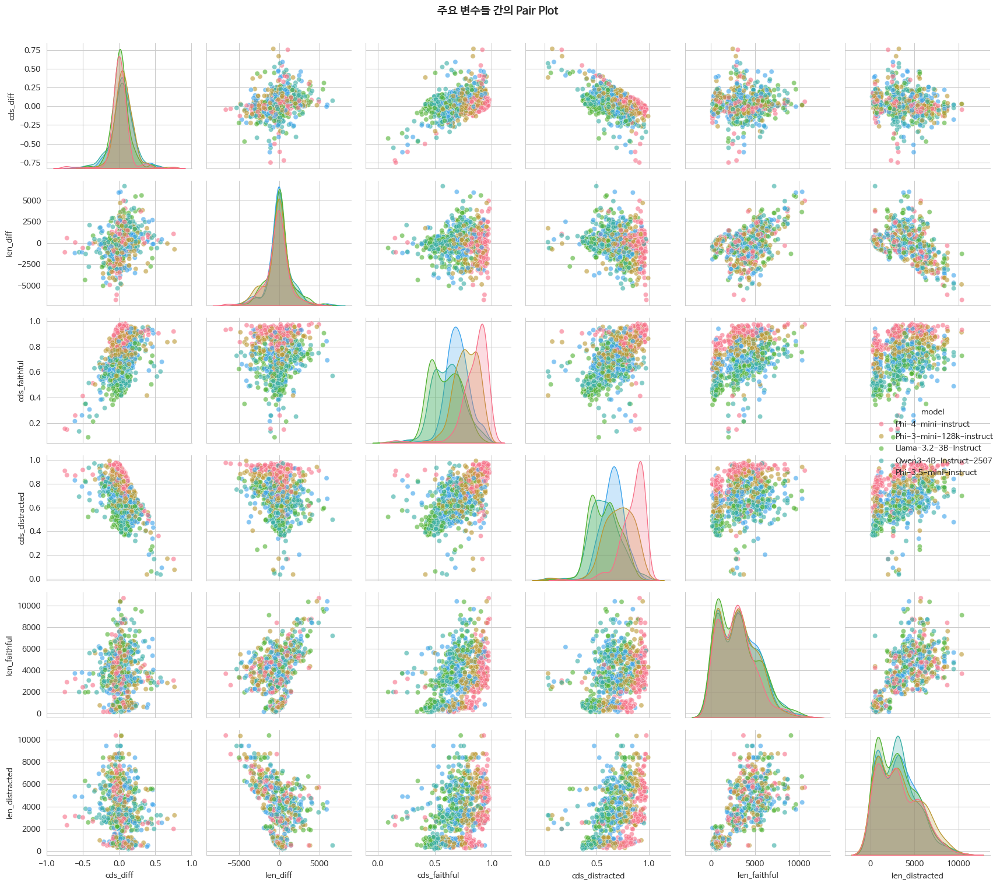

In [15]:
v_group = 'model' # 'dataset'

# Pair Plot - 주요 변수들 간의 관계 시각화
key_vars_for_pairplot = ['cds_diff', 'len_diff', 'total_shift', 'cds_faithful', 'cds_distracted']
key_vars_for_pairplot = ['cds_diff', 'len_diff', 'cds_faithful', 'cds_distracted', 'len_faithful', 'len_distracted']

# 샘플링 (데이터가 클 경우)
sample_size = min(1000, len(df_all))
df_sample = df_all[key_vars_for_pairplot + [v_group]].sample(n=sample_size, random_state=42)

print(f"Pair plot을 위해 {sample_size}개 샘플 사용")
sns.pairplot(df_sample, hue=v_group, diag_kind='kde', plot_kws={'alpha': 0.6}, height=2.5)
plt.suptitle('주요 변수들 간의 Pair Plot', y=1.01, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Pair plot을 위해 1000개 샘플 사용


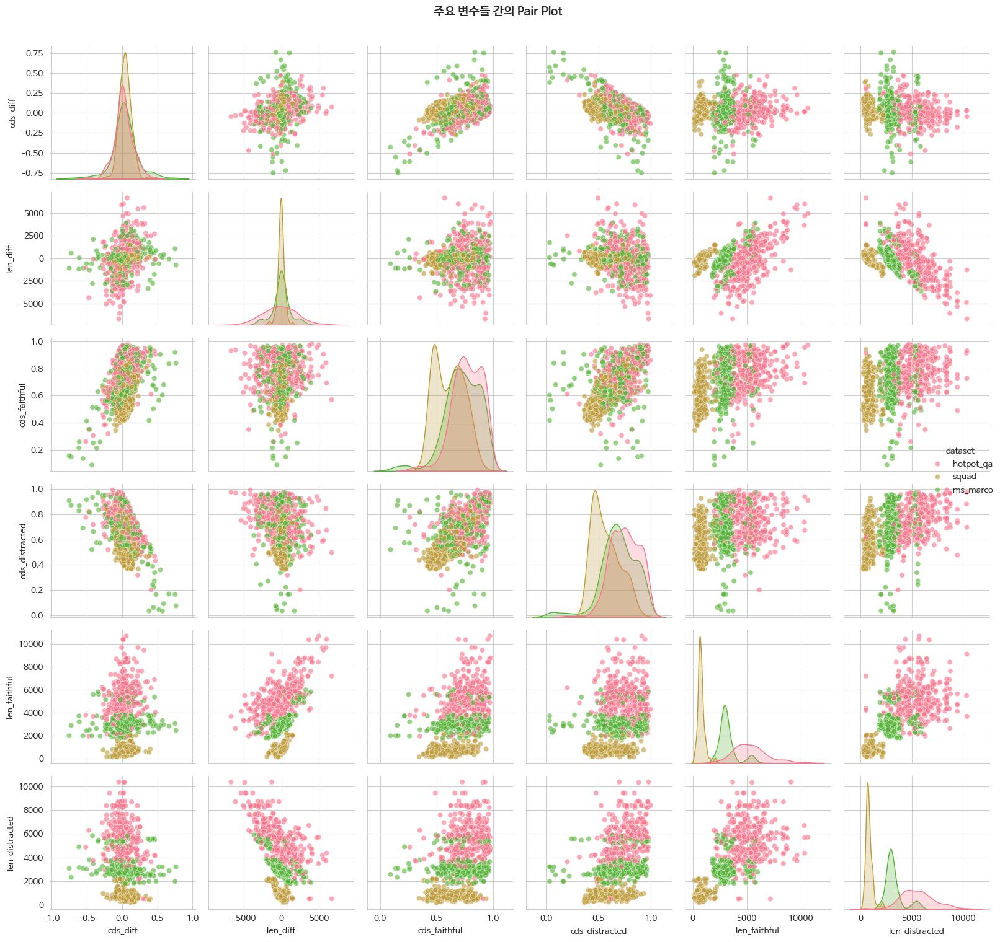

In [16]:
v_group = 'dataset' # 'model'

# Pair Plot - 주요 변수들 간의 관계 시각화
key_vars_for_pairplot = ['cds_diff', 'len_diff', 'total_shift', 'cds_faithful', 'cds_distracted']
key_vars_for_pairplot = ['cds_diff', 'len_diff', 'cds_faithful', 'cds_distracted', 'len_faithful', 'len_distracted']

# 샘플링 (데이터가 클 경우)
sample_size = min(1000, len(df_all))
df_sample = df_all[key_vars_for_pairplot + [v_group]].sample(n=sample_size, random_state=42)

print(f"Pair plot을 위해 {sample_size}개 샘플 사용")
sns.pairplot(df_sample, hue=v_group, diag_kind='kde', plot_kws={'alpha': 0.6}, height=2.5)
plt.suptitle('주요 변수들 간의 Pair Plot', y=1.01, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

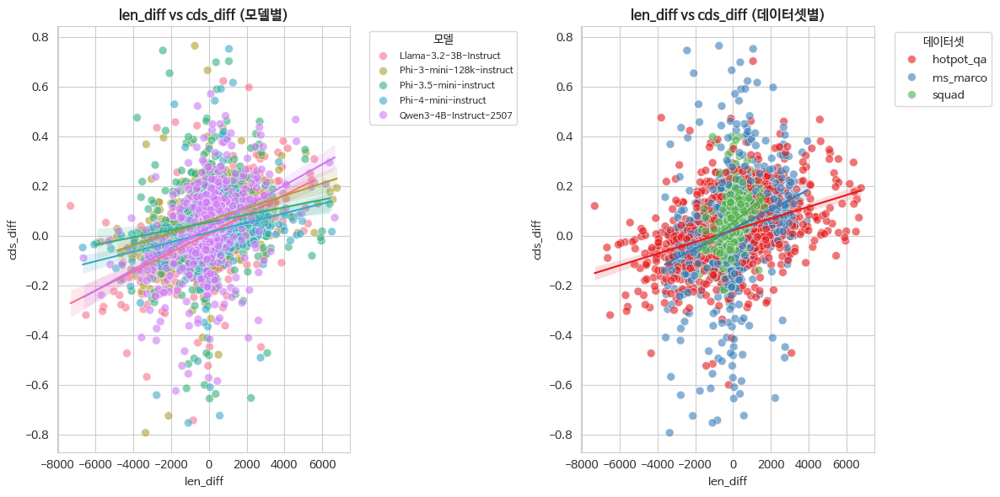

In [17]:
x_val = 'len_diff'; y_val = 'cds_diff'
# 주요 변수 간 산점도 (len_diff vs total_shift)
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df_all, x=x_val, y=y_val, hue='model', alpha=0.6, s=50, palette='husl')
# 모델별로 각각 회귀선 그리기 (scatter와 동일한 색상 사용)
palette = sns.color_palette("husl", n_colors=df_all['model'].nunique())
for idx, model in enumerate(df_all['model'].unique()):
    model_data = df_all[df_all['model'] == model]
    sns.regplot(data=model_data, x=x_val, y=y_val, scatter=False,
                color=palette[idx], line_kws={'linewidth':1.5})
plt.title(f'{x_val} vs {y_val} (모델별)', fontsize=12, fontweight='bold')
plt.xlabel(x_val)
plt.ylabel(y_val)
plt.legend(title='모델', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)

plt.subplot(1, 2, 2)
sns.scatterplot(data=df_all, x=x_val, y=y_val, hue='dataset', alpha=0.6, s=50, palette='Set1')
# 데이터셋별로 각각 회귀선 그리기 (scatter와 동일한 색상 사용)
palette_set1 = sns.color_palette("Set1", n_colors=df_all['dataset'].nunique())
for idx, dataset in enumerate(df_all['dataset'].unique()):
    dataset_data = df_all[df_all['dataset'] == dataset]
    sns.regplot(data=dataset_data, x=x_val, y=y_val, scatter=False,
                color=palette_set1[idx], line_kws={'linewidth':1.5})
plt.title(f'{x_val} vs {y_val} (데이터셋별)', fontsize=12, fontweight='bold')
plt.xlabel(x_val)
plt.ylabel(y_val)
plt.legend(title='데이터셋', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

## 7. 유의성 검정(Significance Test)

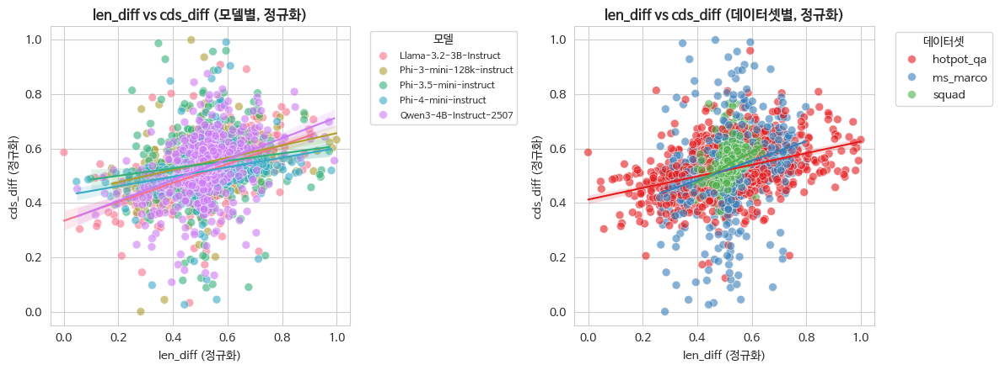

In [18]:
from sklearn.preprocessing import MinMaxScaler

x_val = 'len_diff'; y_val = 'cds_diff'

# 정규화를 위한 스케일러 생성
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

# 데이터 정규화
df_all['len_diff_normalized'] = scaler_x.fit_transform(df_all[[x_val]])
df_all['cds_diff_normalized'] = scaler_y.fit_transform(df_all[[y_val]])

# 주요 변수 간 산점도 (정규화된 데이터)
plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df_all, x='len_diff_normalized', y='cds_diff_normalized', hue='model', alpha=0.6, s=50, palette='husl')
# 모델별로 각각 회귀선 그리기
palette = sns.color_palette("husl", n_colors=df_all['model'].nunique())
for idx, model in enumerate(df_all['model'].unique()):
    model_data = df_all[df_all['model'] == model]
    sns.regplot(data=model_data, x='len_diff_normalized', y='cds_diff_normalized', scatter=False,
                color=palette[idx], line_kws={'linewidth':1.5})
plt.title(f'{x_val} vs {y_val} (모델별, 정규화)', fontsize=12, fontweight='bold')
plt.xlabel(f'{x_val} (정규화)')
plt.ylabel(f'{y_val} (정규화)')
plt.legend(title='모델', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)

plt.subplot(1, 2, 2)
sns.scatterplot(data=df_all, x='len_diff_normalized', y='cds_diff_normalized', hue='dataset', alpha=0.6, s=50, palette='Set1')
# 데이터셋별로 각각 회귀선 그리기
palette_set1 = sns.color_palette("Set1", n_colors=df_all['dataset'].nunique())
for idx, dataset in enumerate(df_all['dataset'].unique()):
    dataset_data = df_all[df_all['dataset'] == dataset]
    sns.regplot(data=dataset_data, x='len_diff_normalized', y='cds_diff_normalized', scatter=False,
                color=palette_set1[idx], line_kws={'linewidth':1.5})
plt.title(f'{x_val} vs {y_val} (데이터셋별, 정규화)', fontsize=12, fontweight='bold')
plt.xlabel(f'{x_val} (정규화)')
plt.ylabel(f'{y_val} (정규화)')
plt.legend(title='데이터셋', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

=== cds_faithful vs cds_distracted Paired T-test ===

전체 데이터:
  평균 cds_faithful: 0.710250
  평균 cds_distracted: 0.675558
  평균 차이 (cds_diff): 0.034692
  t-statistic: 13.2868
  p-value: 3.4688e-39
  결과: 통계적으로 유의한 차이 있음 (α=0.05)


=== 모델별 Paired T-test ===


,모델,샘플 수,cds_faithful 평균,cds_distracted 평균,cds_diff 평균,t-statistic,p-value,유의함 (α=0.05)
0,Llama-3.2-3B-Instruct,600,0.597079,0.587452,0.009627,1.743450,8.176816e-02,No
1,Phi-3-mini-128k-instruct,600,0.775606,0.714144,0.061463,11.917028,1.566188e-29,Yes
2,Phi-3.5-mini-instruct,598,0.700998,0.645366,0.055631,8.411431,2.991988e-16,Yes
3,Phi-4-mini-instruct,600,0.861612,0.848468,0.013144,2.705872,7.006543e-03,Yes
4,Qwen3-4B-Instruct-2507,600,0.615924,0.582258,0.033666,5.161255,3.341476e-07,Yes




=== 데이터셋별 Paired T-test ===


,데이터셋,샘플 수,cds_faithful 평균,cds_distracted 평균,cds_diff 평균,t-statistic,p-value,유의함 (α=0.05)
0,hotpot_qa,998,0.777294,0.755251,0.022043,5.039266,5.546897e-07,Yes
1,ms_marco,1000,0.732778,0.704603,0.028175,4.840670,1.498486e-06,Yes
2,squad,1000,0.620813,0.566979,0.053834,19.259266,1.543159e-70,Yes


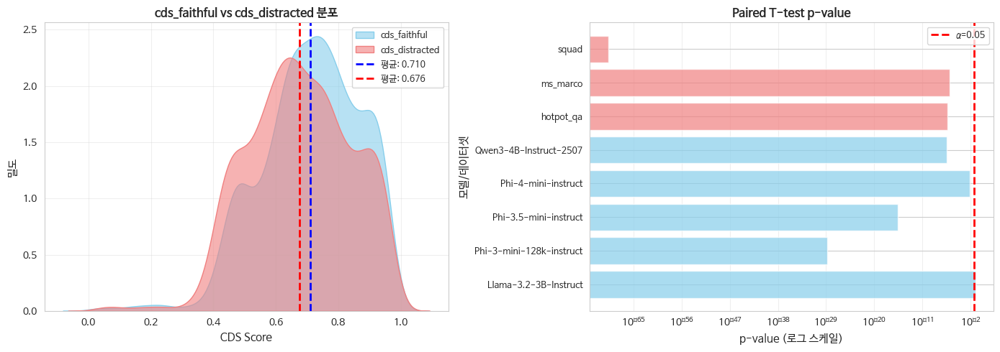

In [19]:
from scipy import stats

# cds_faithful와 cds_distracted 간의 paired t-test
print("=== cds_faithful vs cds_distracted Paired T-test ===\n")

# 전체 데이터에 대한 t-test
valid_idx = df_all[['cds_faithful', 'cds_distracted']].dropna().index
faithful_valid = df_all.loc[valid_idx, 'cds_faithful']
distracted_valid = df_all.loc[valid_idx, 'cds_distracted']

t_stat, p_value = stats.ttest_rel(faithful_valid, distracted_valid)

print(f"전체 데이터:")
print(f"  평균 cds_faithful: {faithful_valid.mean():.6f}")
print(f"  평균 cds_distracted: {distracted_valid.mean():.6f}")
print(f"  평균 차이 (cds_diff): {(faithful_valid - distracted_valid).mean():.6f}")
print(f"  t-statistic: {t_stat:.4f}")
print(f"  p-value: {p_value:.4e}")
print(f"  결과: {'통계적으로 유의한 차이 있음' if p_value < 0.05 else '통계적으로 유의한 차이 없음'} (α=0.05)")

# 모델별 t-test
print("\n\n=== 모델별 Paired T-test ===")
model_ttest_results = []

for model in df_all['model'].unique():
    model_data = df_all[df_all['model'] == model]
    valid_idx = model_data[['cds_faithful', 'cds_distracted']].dropna().index

    if len(valid_idx) > 1:
        faithful_m = model_data.loc[valid_idx, 'cds_faithful']
        distracted_m = model_data.loc[valid_idx, 'cds_distracted']

        t_stat_m, p_value_m = stats.ttest_rel(faithful_m, distracted_m)

        model_ttest_results.append({
            '모델': model,
            '샘플 수': len(valid_idx),
            'cds_faithful 평균': faithful_m.mean(),
            'cds_distracted 평균': distracted_m.mean(),
            'cds_diff 평균': (faithful_m - distracted_m).mean(),
            't-statistic': t_stat_m,
            'p-value': p_value_m,
            '유의함 (α=0.05)': 'Yes' if p_value_m < 0.05 else 'No'
        })

model_ttest_df = pd.DataFrame(model_ttest_results)
display(model_ttest_df)

# 데이터셋별 t-test
print("\n\n=== 데이터셋별 Paired T-test ===")
dataset_ttest_results = []

for dataset in df_all['dataset'].unique():
    dataset_data = df_all[df_all['dataset'] == dataset]
    valid_idx = dataset_data[['cds_faithful', 'cds_distracted']].dropna().index

    if len(valid_idx) > 1:
        faithful_d = dataset_data.loc[valid_idx, 'cds_faithful']
        distracted_d = dataset_data.loc[valid_idx, 'cds_distracted']

        t_stat_d, p_value_d = stats.ttest_rel(faithful_d, distracted_d)

        dataset_ttest_results.append({
            '데이터셋': dataset,
            '샘플 수': len(valid_idx),
            'cds_faithful 평균': faithful_d.mean(),
            'cds_distracted 평균': distracted_d.mean(),
            'cds_diff 평균': (faithful_d - distracted_d).mean(),
            't-statistic': t_stat_d,
            'p-value': p_value_d,
            '유의함 (α=0.05)': 'Yes' if p_value_d < 0.05 else 'No'
        })

dataset_ttest_df = pd.DataFrame(dataset_ttest_results)
display(dataset_ttest_df)

# 시각화: faithful vs distracted 분포 비교 (KDE plot)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 전체 데이터 KDE plot
sns.kdeplot(data=faithful_valid, fill=True, ax=axes[0], color='skyblue', label='cds_faithful', alpha=0.6)
sns.kdeplot(data=distracted_valid, fill=True, ax=axes[0], color='lightcoral', label='cds_distracted', alpha=0.6)
axes[0].axvline(faithful_valid.mean(), color='blue', linestyle='--', linewidth=2, label=f'평균: {faithful_valid.mean():.3f}')
axes[0].axvline(distracted_valid.mean(), color='red', linestyle='--', linewidth=2, label=f'평균: {distracted_valid.mean():.3f}')
axes[0].set_xlabel('CDS Score', fontsize=11)
axes[0].set_ylabel('밀도', fontsize=11)
axes[0].set_title('cds_faithful vs cds_distracted 분포', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper right', fontsize=9)
axes[0].grid(alpha=0.3)

# p-value 시각화 (로그 스케일)
all_pvalues = list(model_ttest_df['p-value']) + list(dataset_ttest_df['p-value'])
all_labels = list(model_ttest_df['모델']) + list(dataset_ttest_df['데이터셋'])
colors = ['skyblue'] * len(model_ttest_df) + ['lightcoral'] * len(dataset_ttest_df)

axes[1].barh(range(len(all_pvalues)), all_pvalues, color=colors, alpha=0.7)
axes[1].axvline(0.05, color='red', linestyle='--', linewidth=2, label='α=0.05')
axes[1].set_xlabel('p-value (로그 스케일)', fontsize=11)
axes[1].set_ylabel('모델/데이터셋', fontsize=11)
axes[1].set_title('Paired T-test p-value', fontsize=12, fontweight='bold')
axes[1].set_yticks(range(len(all_labels)))
axes[1].set_yticklabels(all_labels, fontsize=9)
axes[1].set_xscale('log')
axes[1].legend(loc='upper right', fontsize=9)
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

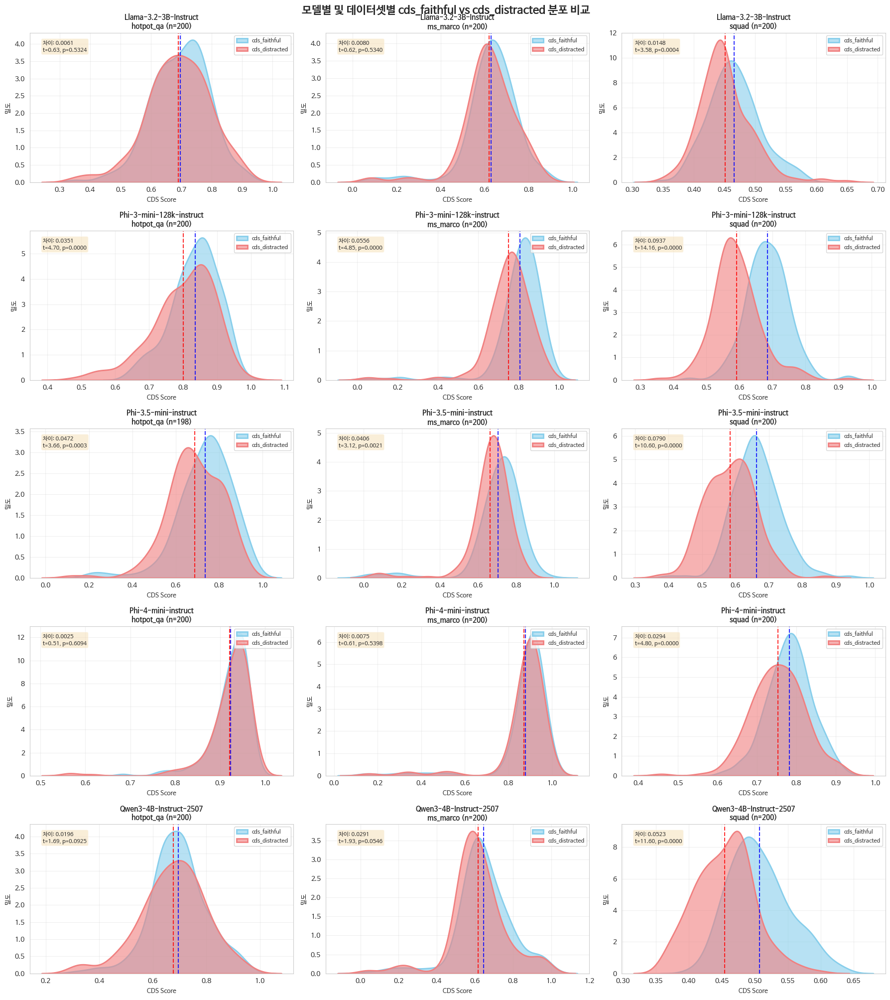

In [20]:
# 모델별 및 데이터셋별 faithful vs distracted 분포 비교 (KDE plot)
fig, axes = plt.subplots(5, 3, figsize=(18, 20))

models = df_all['model'].unique()
datasets = df_all['dataset'].unique()

for i, model in enumerate(models):
    for j, dataset in enumerate(datasets):
        ax = axes[i, j]

        # 해당 모델-데이터셋 조합의 데이터 필터링
        mask = (df_all['model'] == model) & (df_all['dataset'] == dataset)
        data_subset = df_all[mask]

        # 결측치 제거
        valid_idx = data_subset[['cds_faithful', 'cds_distracted']].dropna().index

        if len(valid_idx) > 0:
            faithful_subset = data_subset.loc[valid_idx, 'cds_faithful']
            distracted_subset = data_subset.loc[valid_idx, 'cds_distracted']

            # KDE plot
            sns.kdeplot(data=faithful_subset, fill=True, ax=ax, color='skyblue',
                       label='cds_faithful', alpha=0.6, linewidth=2)
            sns.kdeplot(data=distracted_subset, fill=True, ax=ax, color='lightcoral',
                       label='cds_distracted', alpha=0.6, linewidth=2)

            # 평균선 추가
            ax.axvline(faithful_subset.mean(), color='blue', linestyle='--',
                      linewidth=1.5, alpha=0.8)
            ax.axvline(distracted_subset.mean(), color='red', linestyle='--',
                      linewidth=1.5, alpha=0.8)

            # 제목 및 레이블
            ax.set_title(f'{model}\n{dataset} (n={len(valid_idx)})',
                        fontsize=10, fontweight='bold')
            ax.set_xlabel('CDS Score', fontsize=9)
            ax.set_ylabel('밀도', fontsize=9)
            ax.legend(loc='upper right', fontsize=8)
            ax.grid(alpha=0.3)

            # 차이값 텍스트 추가
            diff_mean = faithful_subset.mean() - distracted_subset.mean()
            # t-test 수행
            if len(valid_idx) > 1:
                t_stat_subset, p_value_subset = stats.ttest_rel(faithful_subset, distracted_subset)

                ax.text(0.05, 0.95, f'차이: {diff_mean:.4f}\nt={t_stat_subset:.2f}, p={p_value_subset:.4f}',
                       transform=ax.transAxes, fontsize=8,
                       verticalalignment='top',
                       bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        else:
            ax.text(0.5, 0.5, 'No Data', ha='center', va='center', fontsize=12)
            ax.set_title(f'{model}\n{dataset}', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.suptitle('모델별 및 데이터셋별 cds_faithful vs cds_distracted 분포 비교',
             fontsize=16, fontweight='bold', y=1.001)
plt.show()

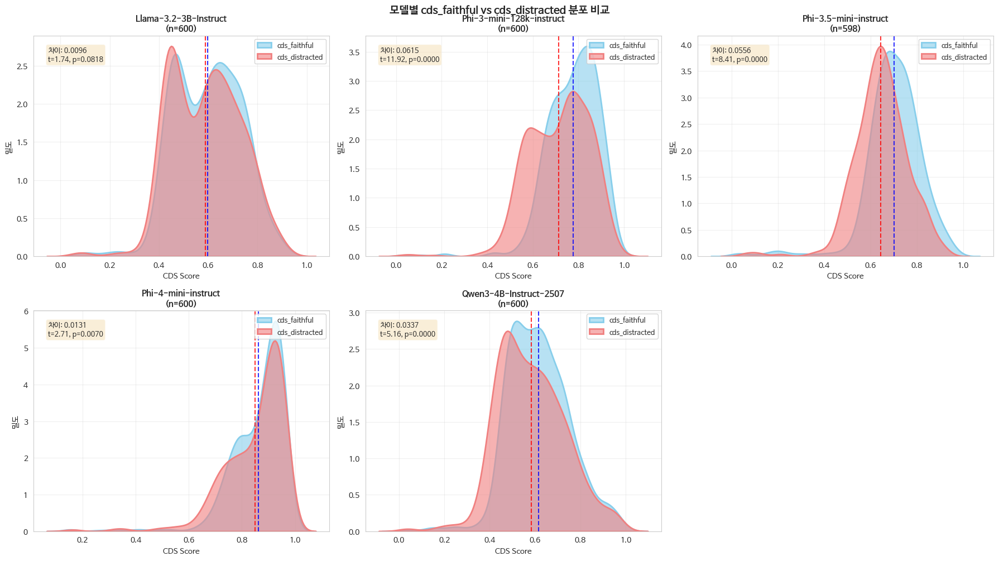

In [21]:
# 모델별 faithful vs distracted 분포 비교 (KDE plot)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, model in enumerate(models):
    if idx >= len(axes):
        break

    ax = axes[idx]

    # 해당 모델의 데이터 필터링
    model_data = df_all[df_all['model'] == model]

    # 결측치 제거
    valid_idx = model_data[['cds_faithful', 'cds_distracted']].dropna().index

    if len(valid_idx) > 0:
        faithful_m = model_data.loc[valid_idx, 'cds_faithful']
        distracted_m = model_data.loc[valid_idx, 'cds_distracted']

        # KDE plot
        sns.kdeplot(data=faithful_m, fill=True, ax=ax, color='skyblue',
                   label='cds_faithful', alpha=0.6, linewidth=2)
        sns.kdeplot(data=distracted_m, fill=True, ax=ax, color='lightcoral',
                   label='cds_distracted', alpha=0.6, linewidth=2)

        # 평균선 추가
        ax.axvline(faithful_m.mean(), color='blue', linestyle='--',
                  linewidth=1.5, alpha=0.8)
        ax.axvline(distracted_m.mean(), color='red', linestyle='--',
                  linewidth=1.5, alpha=0.8)

        # 제목 및 레이블
        ax.set_title(f'{model}\n(n={len(valid_idx)})',
                    fontsize=11, fontweight='bold')
        ax.set_xlabel('CDS Score', fontsize=10)
        ax.set_ylabel('밀도', fontsize=10)
        ax.legend(loc='upper right', fontsize=9)
        ax.grid(alpha=0.3)

        # 차이값 및 통계 정보 추가
        diff_mean = faithful_m.mean() - distracted_m.mean()

        # t-test 수행
        if len(valid_idx) > 1:
            t_stat_m, p_value_m = stats.ttest_rel(faithful_m, distracted_m)

            ax.text(0.05, 0.95, f'차이: {diff_mean:.4f}\nt={t_stat_m:.2f}, p={p_value_m:.4f}',
                   transform=ax.transAxes, fontsize=9,
                   verticalalignment='top',
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    else:
        ax.text(0.5, 0.5, 'No Data', ha='center', va='center', fontsize=12)
        ax.set_title(f'{model}', fontsize=11, fontweight='bold')

# 남은 subplot 제거
if len(models) < 6:
    fig.delaxes(axes[5])

plt.tight_layout()
plt.suptitle('모델별 cds_faithful vs cds_distracted 분포 비교',
             fontsize=14, fontweight='bold', y=1.001)
plt.show()

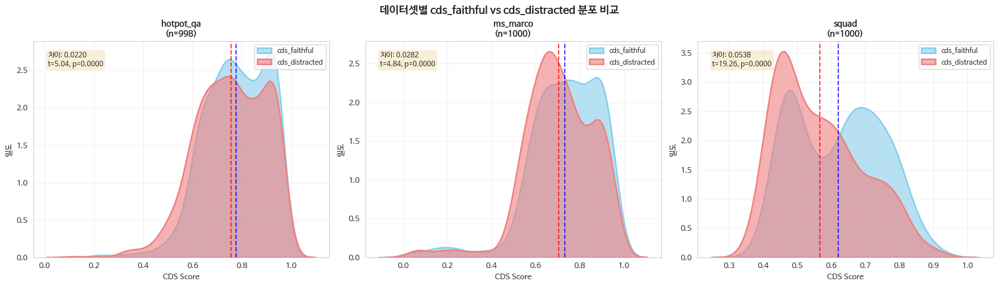

In [22]:
# 데이터셋별 faithful vs distracted 분포 비교 (KDE plot)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, dataset in enumerate(datasets):
    ax = axes[idx]

    # 해당 데이터셋의 데이터 필터링
    dataset_data = df_all[df_all['dataset'] == dataset]

    # 결측치 제거
    valid_idx = dataset_data[['cds_faithful', 'cds_distracted']].dropna().index

    if len(valid_idx) > 0:
        faithful_d = dataset_data.loc[valid_idx, 'cds_faithful']
        distracted_d = dataset_data.loc[valid_idx, 'cds_distracted']

        # KDE plot
        sns.kdeplot(data=faithful_d, fill=True, ax=ax, color='skyblue',
                   label='cds_faithful', alpha=0.6, linewidth=2)
        sns.kdeplot(data=distracted_d, fill=True, ax=ax, color='lightcoral',
                   label='cds_distracted', alpha=0.6, linewidth=2)

        # 평균선 추가
        ax.axvline(faithful_d.mean(), color='blue', linestyle='--',
                  linewidth=1.5, alpha=0.8)
        ax.axvline(distracted_d.mean(), color='red', linestyle='--',
                  linewidth=1.5, alpha=0.8)

        # 제목 및 레이블
        ax.set_title(f'{dataset}\n(n={len(valid_idx)})',
                    fontsize=11, fontweight='bold')
        ax.set_xlabel('CDS Score', fontsize=10)
        ax.set_ylabel('밀도', fontsize=10)
        ax.legend(loc='upper right', fontsize=9)
        ax.grid(alpha=0.3)

        # 차이값 및 통계 정보 추가
        diff_mean = faithful_d.mean() - distracted_d.mean()

        # t-test 수행
        if len(valid_idx) > 1:
            t_stat_d, p_value_d = stats.ttest_rel(faithful_d, distracted_d)

            ax.text(0.05, 0.95, f'차이: {diff_mean:.4f}\nt={t_stat_d:.2f}, p={p_value_d:.4f}',
                   transform=ax.transAxes, fontsize=9,
                   verticalalignment='top',
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    else:
        ax.text(0.5, 0.5, 'No Data', ha='center', va='center', fontsize=12)
        ax.set_title(f'{dataset}', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.suptitle('데이터셋별 cds_faithful vs cds_distracted 분포 비교',
             fontsize=14, fontweight='bold', y=1.02)
plt.show()

=== len_diff 그룹별 범위 및 통계 ===


,min,max,mean,count
len_diff_group,,,,
Low,-7333,0,-1014.240473,1522
High,1,6782,1009.142760,1478


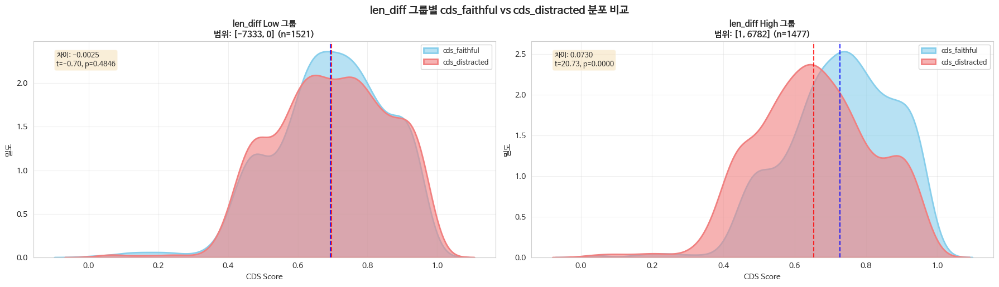



=== len_diff 그룹별 Paired T-test 결과 ===


,len_diff 그룹,len_diff 범위,샘플 수,cds_faithful 평균,cds_distracted 평균,cds_diff 평균,t-statistic,p-value,유의함 (α=0.05)
0,Low,"[-7333, 0]",1521,0.693644,0.696161,-0.002517,-0.699174,4.845500e-01,No
1,High,"[1, 6782]",1477,0.727351,0.654341,0.073010,20.734144,5.137388e-84,Yes


In [23]:
# len_diff를 기준으로 2그룹으로 나누기 (tertiles)
df_all['len_diff_group'] = pd.cut(df_all['len_diff'], bins=[-np.inf, 0, np.inf], labels=['Low', 'High'])

# 그룹별 통계 확인
print("=== len_diff 그룹별 범위 및 통계 ===")
group_stats = df_all.groupby('len_diff_group')['len_diff'].agg(['min', 'max', 'mean', 'count'])
display(group_stats)

# 그룹별 faithful vs distracted 분포 비교 (KDE plot)
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

for idx, group in enumerate(['Low', 'High']):
    ax = axes[idx]

    # 해당 그룹의 데이터 필터링
    group_data = df_all[df_all['len_diff_group'] == group]

    # 결측치 제거
    valid_idx = group_data[['cds_faithful', 'cds_distracted']].dropna().index

    if len(valid_idx) > 0:
        faithful_g = group_data.loc[valid_idx, 'cds_faithful']
        distracted_g = group_data.loc[valid_idx, 'cds_distracted']

        # KDE plot
        sns.kdeplot(data=faithful_g, fill=True, ax=ax, color='skyblue',
                   label='cds_faithful', alpha=0.6, linewidth=2)
        sns.kdeplot(data=distracted_g, fill=True, ax=ax, color='lightcoral',
                   label='cds_distracted', alpha=0.6, linewidth=2)

        # 평균선 추가
        ax.axvline(faithful_g.mean(), color='blue', linestyle='--',
                  linewidth=1.5, alpha=0.8)
        ax.axvline(distracted_g.mean(), color='red', linestyle='--',
                  linewidth=1.5, alpha=0.8)

        # 제목 및 레이블
        len_diff_range = f"[{group_data['len_diff'].min():.0f}, {group_data['len_diff'].max():.0f}]"
        ax.set_title(f'len_diff {group} 그룹\n범위: {len_diff_range} (n={len(valid_idx)})',
                    fontsize=11, fontweight='bold')
        ax.set_xlabel('CDS Score', fontsize=10)
        ax.set_ylabel('밀도', fontsize=10)
        ax.legend(loc='upper right', fontsize=9)
        ax.grid(alpha=0.3)

        # 차이값 및 통계 정보 추가
        diff_mean = faithful_g.mean() - distracted_g.mean()

        # t-test 수행
        if len(valid_idx) > 1:
            t_stat_g, p_value_g = stats.ttest_rel(faithful_g, distracted_g)

            ax.text(0.05, 0.95, f'차이: {diff_mean:.4f}\nt={t_stat_g:.2f}, p={p_value_g:.4f}',
                   transform=ax.transAxes, fontsize=9,
                   verticalalignment='top',
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    else:
        ax.text(0.5, 0.5, 'No Data', ha='center', va='center', fontsize=12)
        ax.set_title(f'len_diff {group} 그룹', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.suptitle('len_diff 그룹별 cds_faithful vs cds_distracted 분포 비교',
             fontsize=14, fontweight='bold', y=1.02)
plt.show()

# 그룹별 t-test 결과 요약
print("\n\n=== len_diff 그룹별 Paired T-test 결과 ===")
group_ttest_results = []

for group in ['Low', 'Medium', 'High']:
    group_data = df_all[df_all['len_diff_group'] == group]
    valid_idx = group_data[['cds_faithful', 'cds_distracted']].dropna().index

    if len(valid_idx) > 1:
        faithful_g = group_data.loc[valid_idx, 'cds_faithful']
        distracted_g = group_data.loc[valid_idx, 'cds_distracted']

        t_stat_g, p_value_g = stats.ttest_rel(faithful_g, distracted_g)

        group_ttest_results.append({
            'len_diff 그룹': group,
            'len_diff 범위': f"[{group_data['len_diff'].min()}, {group_data['len_diff'].max()}]",
            '샘플 수': len(valid_idx),
            'cds_faithful 평균': faithful_g.mean(),
            'cds_distracted 평균': distracted_g.mean(),
            'cds_diff 평균': (faithful_g - distracted_g).mean(),
            't-statistic': t_stat_g,
            'p-value': p_value_g,
            '유의함 (α=0.05)': 'Yes' if p_value_g < 0.05 else 'No'
        })

group_ttest_df = pd.DataFrame(group_ttest_results)
display(group_ttest_df)

## 8. 이상치 탐지 및 분석

In [24]:
# IQR 방법을 사용한 이상치 탐지
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

# 주요 메트릭별 이상치 개수 확인
print("=== 주요 메트릭별 이상치 개수 (IQR 방법) ===")
outlier_summary = []

for metric in key_metrics:
    outliers, lower, upper = detect_outliers_iqr(df_all, metric)
    outlier_summary.append({
        '메트릭': metric,
        '이상치 개수': len(outliers),
        '이상치 비율(%)': (len(outliers) / len(df_all)) * 100,
        '하한': lower,
        '상한': upper
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df)

=== 주요 메트릭별 이상치 개수 (IQR 방법) ===


,메트릭,이상치 개수,이상치 비율(%),하한,상한
0,cds_faithful,32,1.066667,0.288260,1.153868
1,cds_distracted,17,0.566667,0.201122,1.157257
2,cds_diff,173,5.766667,-0.235367,0.309521
3,len_diff,511,17.033333,-2104.250000,2081.750000
4,total_shift,655,21.833333,-118.907680,130.658754


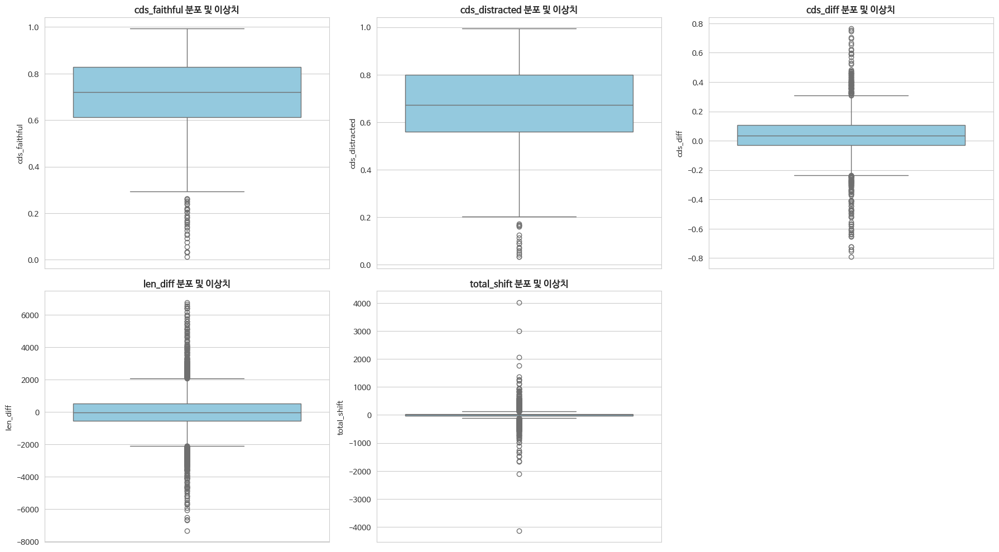

In [25]:
# Box Plot으로 이상치 시각화
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, metric in enumerate(key_metrics):
    ax = axes[idx]
    sns.boxplot(data=df_all, y=metric, ax=ax, color='skyblue')
    ax.set_title(f'{metric} 분포 및 이상치', fontsize=12, fontweight='bold')
    ax.set_ylabel(metric)

# 남은 subplot 제거
if len(key_metrics) < 6:
    fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

=== len_diff 이상치 제거 전후 비교 ===
제거 전 데이터 크기: (3000, 16)
이상치 개수: 511 (17.03%)
하한: -2104.25, 상한: 2081.75
제거 후 데이터 크기: (2489, 16)

=== 제거 후 len_diff 기본 통계량 ===


,len_diff
count,2489.000000
mean,7.180796
std,771.248972
min,-2104.000000
25%,-374.000000
50%,-6.000000
75%,388.000000
max,2072.000000


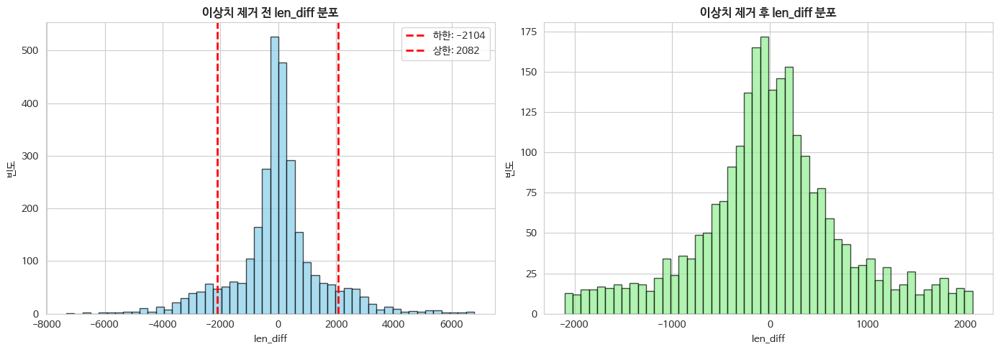

In [26]:
# len_diff 이상치 제거
outliers_len_diff, lower_len_diff, upper_len_diff = detect_outliers_iqr(df_all, 'len_diff')

print(f"=== len_diff 이상치 제거 전후 비교 ===")
print(f"제거 전 데이터 크기: {df_all.shape}")
print(f"이상치 개수: {len(outliers_len_diff)} ({len(outliers_len_diff)/len(df_all)*100:.2f}%)")
print(f"하한: {lower_len_diff:.2f}, 상한: {upper_len_diff:.2f}")

# 이상치 제거
df_filtered = df_all[(df_all['len_diff'] >= lower_len_diff) & (df_all['len_diff'] <= upper_len_diff)]

print(f"제거 후 데이터 크기: {df_filtered.shape}")
print(f"\n=== 제거 후 len_diff 기본 통계량 ===")
display(df_filtered['len_diff'].describe())

# 제거 전후 비교 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_all['len_diff'], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[0].axvline(lower_len_diff, color='red', linestyle='--', linewidth=2, label=f'하한: {lower_len_diff:.0f}')
axes[0].axvline(upper_len_diff, color='red', linestyle='--', linewidth=2, label=f'상한: {upper_len_diff:.0f}')
axes[0].set_title('이상치 제거 전 len_diff 분포', fontsize=12, fontweight='bold')
axes[0].set_xlabel('len_diff')
axes[0].set_ylabel('빈도')
axes[0].legend()

axes[1].hist(df_filtered['len_diff'], bins=50, color='lightgreen', edgecolor='black', alpha=0.7)
axes[1].set_title('이상치 제거 후 len_diff 분포', fontsize=12, fontweight='bold')
axes[1].set_xlabel('len_diff')
axes[1].set_ylabel('빈도')

plt.tight_layout()
plt.show()

=== len_diff 그룹별 범위 및 통계 (필터링된 데이터) ===


,min,max,mean,count
len_diff_group,,,,
Low,-2104,-219,-782.529483,831
Medium,-218,226,2.655797,828
High,228,2072,802.356627,830


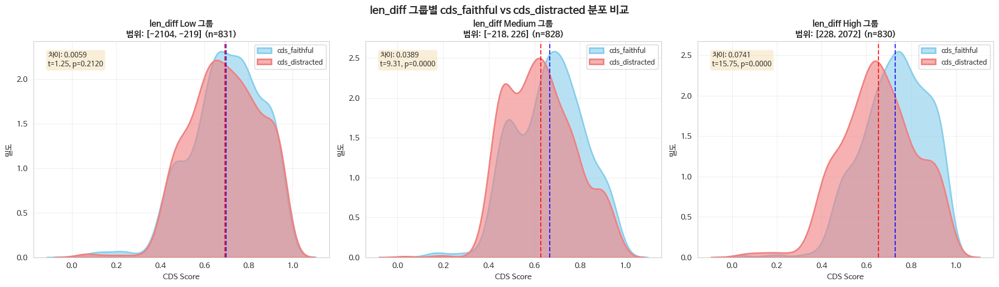



=== len_diff 그룹별 Paired T-test 결과 ===


,len_diff 그룹,len_diff 범위,샘플 수,cds_faithful 평균,cds_distracted 평균,cds_diff 평균,t-statistic,p-value,유의함 (α=0.05)
0,Low,"[-2104, -219]",831,0.698672,0.692790,0.005882,1.249003,2.120161e-01,No
1,Medium,"[-218, 226]",828,0.666823,0.627949,0.038874,9.311713,1.107197e-19,Yes
2,High,"[228, 2072]",830,0.727826,0.653762,0.074064,15.754227,4.114302e-49,Yes


In [27]:
# len_diff를 기준으로 3그룹으로 나누기 (tertiles)
df_filtered['len_diff_group'] = pd.qcut(df_filtered['len_diff'], q=3, labels=['Low', 'Medium', 'High'])

# 그룹별 통계 확인
print("=== len_diff 그룹별 범위 및 통계 (필터링된 데이터) ===")
group_stats_filtered = df_filtered.groupby('len_diff_group')['len_diff'].agg(['min', 'max', 'mean', 'count'])
display(group_stats_filtered)

# 그룹별 faithful vs distracted 분포 비교 (KDE plot)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, group in enumerate(['Low', 'Medium', 'High']):
    ax = axes[idx]

    # 해당 그룹의 데이터 필터링
    group_data = df_filtered[df_filtered['len_diff_group'] == group]

    # 결측치 제거
    valid_idx = group_data[['cds_faithful', 'cds_distracted']].dropna().index

    if len(valid_idx) > 0:
        faithful_g = group_data.loc[valid_idx, 'cds_faithful']
        distracted_g = group_data.loc[valid_idx, 'cds_distracted']

        # KDE plot
        sns.kdeplot(data=faithful_g, fill=True, ax=ax, color='skyblue',
                   label='cds_faithful', alpha=0.6, linewidth=2)
        sns.kdeplot(data=distracted_g, fill=True, ax=ax, color='lightcoral',
                   label='cds_distracted', alpha=0.6, linewidth=2)

        # 평균선 추가
        ax.axvline(faithful_g.mean(), color='blue', linestyle='--',
                  linewidth=1.5, alpha=0.8)
        ax.axvline(distracted_g.mean(), color='red', linestyle='--',
                  linewidth=1.5, alpha=0.8)

        # 제목 및 레이블
        len_diff_range = f"[{group_data['len_diff'].min():.0f}, {group_data['len_diff'].max():.0f}]"
        ax.set_title(f'len_diff {group} 그룹\n범위: {len_diff_range} (n={len(valid_idx)})',
                    fontsize=11, fontweight='bold')
        ax.set_xlabel('CDS Score', fontsize=10)
        ax.set_ylabel('밀도', fontsize=10)
        ax.legend(loc='upper right', fontsize=9)
        ax.grid(alpha=0.3)

        # 차이값 및 통계 정보 추가
        diff_mean = faithful_g.mean() - distracted_g.mean()

        # t-test 수행
        if len(valid_idx) > 1:
            t_stat_g, p_value_g = stats.ttest_rel(faithful_g, distracted_g)

            ax.text(0.05, 0.95, f'차이: {diff_mean:.4f}\nt={t_stat_g:.2f}, p={p_value_g:.4f}',
                   transform=ax.transAxes, fontsize=9,
                   verticalalignment='top',
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    else:
        ax.text(0.5, 0.5, 'No Data', ha='center', va='center', fontsize=12)
        ax.set_title(f'len_diff {group} 그룹', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.suptitle('len_diff 그룹별 cds_faithful vs cds_distracted 분포 비교',
             fontsize=14, fontweight='bold', y=1.02)
plt.show()

# 그룹별 t-test 결과 요약
print("\n\n=== len_diff 그룹별 Paired T-test 결과 ===")
group_ttest_results = []

for group in ['Low', 'Medium', 'High']:
    group_data = df_filtered[df_filtered['len_diff_group'] == group]
    valid_idx = group_data[['cds_faithful', 'cds_distracted']].dropna().index

    if len(valid_idx) > 1:
        faithful_g = group_data.loc[valid_idx, 'cds_faithful']
        distracted_g = group_data.loc[valid_idx, 'cds_distracted']

        t_stat_g, p_value_g = stats.ttest_rel(faithful_g, distracted_g)

        group_ttest_results.append({
            'len_diff 그룹': group,
            'len_diff 범위': f"[{group_data['len_diff'].min()}, {group_data['len_diff'].max()}]",
            '샘플 수': len(valid_idx),
            'cds_faithful 평균': faithful_g.mean(),
            'cds_distracted 평균': distracted_g.mean(),
            'cds_diff 평균': (faithful_g - distracted_g).mean(),
            't-statistic': t_stat_g,
            'p-value': p_value_g,
            '유의함 (α=0.05)': 'Yes' if p_value_g < 0.05 else 'No'
        })

group_ttest_df = pd.DataFrame(group_ttest_results)
display(group_ttest_df)

Pair plot을 위해 1000개 샘플 사용


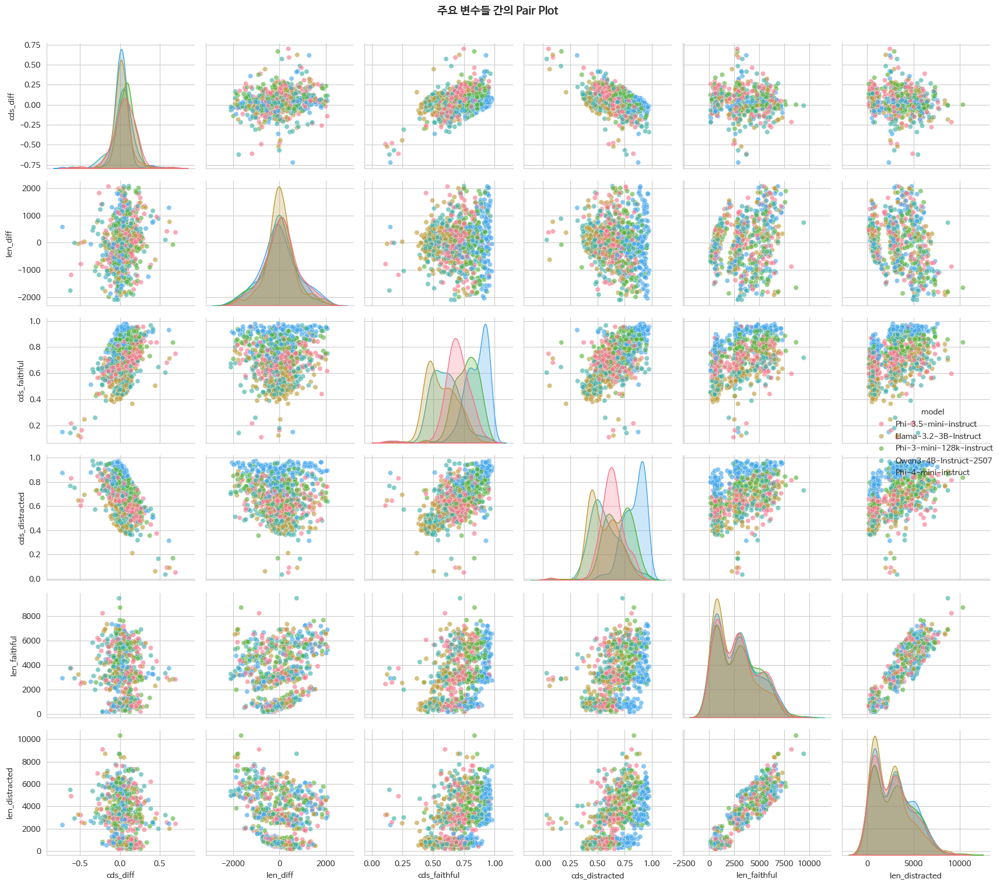

In [28]:
v_group = 'model' # 'dataset'

# Pair Plot - 주요 변수들 간의 관계 시각화
key_vars_for_pairplot = ['cds_diff', 'len_diff', 'total_shift', 'cds_faithful', 'cds_distracted']
key_vars_for_pairplot = ['cds_diff', 'len_diff', 'cds_faithful', 'cds_distracted', 'len_faithful', 'len_distracted']

# 샘플링 (데이터가 클 경우)
sample_size = min(1000, len(df_filtered))
df_sample = df_filtered[key_vars_for_pairplot + [v_group]].sample(n=sample_size, random_state=42)

print(f"Pair plot을 위해 {sample_size}개 샘플 사용")
sns.pairplot(df_sample, hue=v_group, diag_kind='kde', plot_kws={'alpha': 0.6}, height=2.5)
plt.suptitle('주요 변수들 간의 Pair Plot', y=1.01, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Pair plot을 위해 1000개 샘플 사용


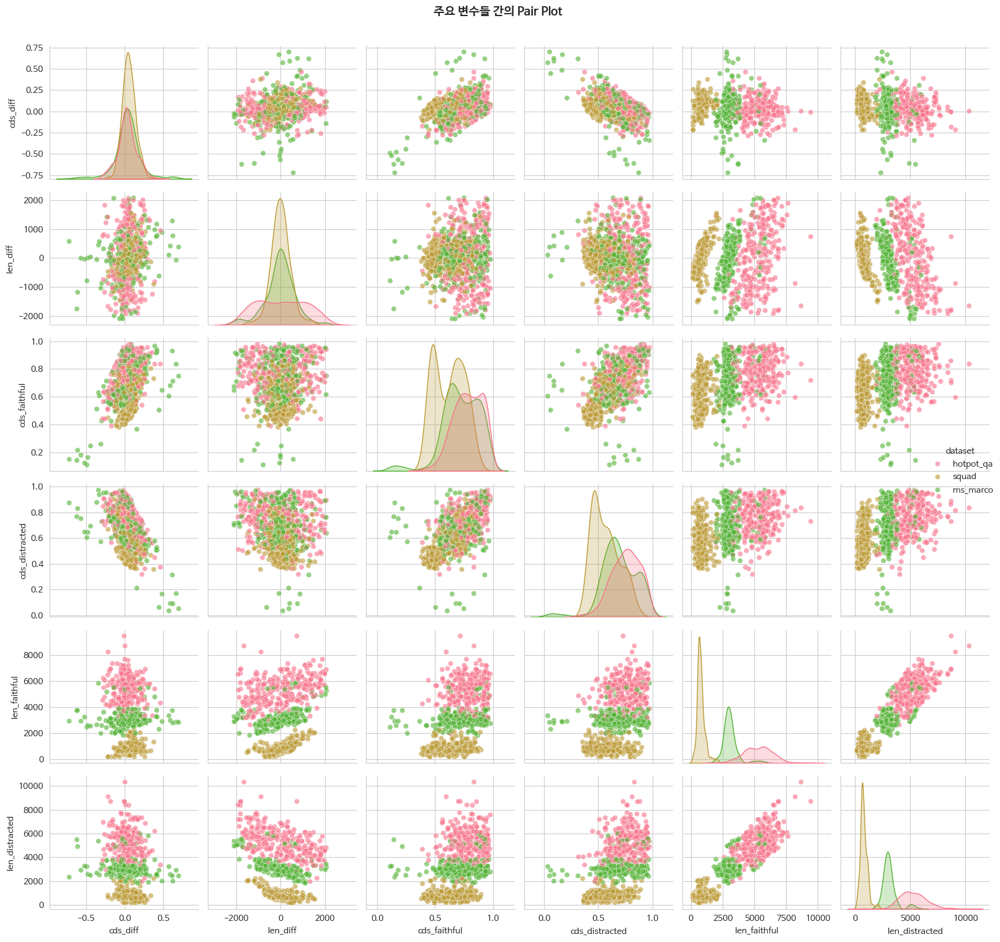

In [29]:
v_group = 'dataset' # 'dataset'

# Pair Plot - 주요 변수들 간의 관계 시각화
key_vars_for_pairplot = ['cds_diff', 'len_diff', 'total_shift', 'cds_faithful', 'cds_distracted']
key_vars_for_pairplot = ['cds_diff', 'len_diff', 'cds_faithful', 'cds_distracted', 'len_faithful', 'len_distracted']

# 샘플링 (데이터가 클 경우)
sample_size = min(1000, len(df_filtered))
df_sample = df_filtered[key_vars_for_pairplot + [v_group]].sample(n=sample_size, random_state=42)

print(f"Pair plot을 위해 {sample_size}개 샘플 사용")
sns.pairplot(df_sample, hue=v_group, diag_kind='kde', plot_kws={'alpha': 0.6}, height=2.5)
plt.suptitle('주요 변수들 간의 Pair Plot', y=1.01, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 9. 종합 요약 및 인사이트

In [30]:
# 모델별 종합 순위 (cds_diff 기준 - 높을수록 좋음)
model_ranking = df_all.groupby('model')['cds_diff'].mean().sort_values(ascending=False)

print("=== 모델별 종합 순위 (cds_diff 평균 기준) ===")
print("\n순위\t모델\t\t\t\tcds_diff 평균")
print("-" * 60)
for rank, (model, score) in enumerate(model_ranking.items(), 1):
    print(f"{rank}\t{model:30s}\t{score:.6f}")

# 데이터셋별 난이도 분석 (여러 메트릭 종합)
dataset_difficulty = df_all.groupby('dataset')[key_metrics].mean()

print("\n\n=== 데이터셋별 평균 메트릭 ===")
display(dataset_difficulty.round(4))

# 최고 성능 모델-데이터셋 조합
print("\n\n=== 모델-데이터셋 조합별 최고 성능 (cds_diff 기준) ===")
best_combinations = df_all.groupby(['model', 'dataset'])['cds_diff'].mean().sort_values(ascending=False).head(10)
display(best_combinations.to_frame('cds_diff 평균'))

=== 모델별 종합 순위 (cds_diff 평균 기준) ===

순위	모델				cds_diff 평균
------------------------------------------------------------
1	Phi-3-mini-128k-instruct      	0.061463
2	Phi-3.5-mini-instruct         	0.055631
3	Qwen3-4B-Instruct-2507        	0.033666
4	Phi-4-mini-instruct           	0.013144
5	Llama-3.2-3B-Instruct         	0.009627


=== 데이터셋별 평균 메트릭 ===


,cds_faithful,cds_distracted,cds_diff,len_diff,total_shift
dataset,,,,,
hotpot_qa,0.7771,0.7552,0.0220,-42.437,NaN
ms_marco,0.7328,0.7046,0.0282,-2.602,2.2157
squad,0.6208,0.5670,0.0538,-7.122,7.6705




=== 모델-데이터셋 조합별 최고 성능 (cds_diff 기준) ===


cds_diff 평균
model                    dataset               
Phi-3-mini-128k-instruct squad         0.093653
Phi-3.5-mini-instruct    squad         0.078990
Phi-3-mini-128k-instruct ms_marco      0.055638
Qwen3-4B-Instruct-2507   squad         0.052294
Phi-3.5-mini-instruct    hotpot_qa     0.047189
                         ms_marco      0.040631
Phi-3-mini-128k-instruct hotpot_qa     0.035097
Phi-4-mini-instruct      squad         0.029393
Qwen3-4B-Instruct-2507   ms_marco      0.029130
                         hotpot_qa     0.019574

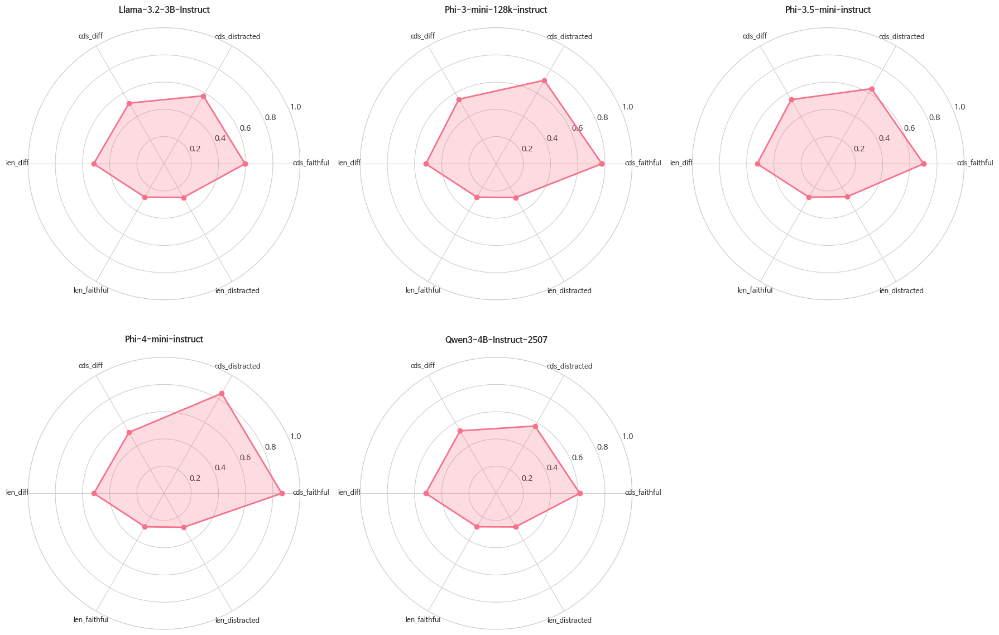

In [31]:
# 종합 시각화: 모델별 레이더 차트
from math import pi

# 모델별 평균값 계산 (정규화)
models = df_all['model'].unique()
metrics_for_radar = ['cds_faithful', 'cds_distracted', 'cds_diff', 'len_diff', 'len_faithful', 'len_distracted']

fig, axes = plt.subplots(2, 3, figsize=(18, 12), subplot_kw=dict(projection='polar'))
axes = axes.flatten()

for idx, model in enumerate(models):
    if idx >= len(axes):
        break

    ax = axes[idx]
    model_data = df_all[df_all['model'] == model][metrics_for_radar].mean()

    # 데이터 정규화 (0-1 범위로)
    normalized_data = []
    for metric in metrics_for_radar:
        min_val = df_all[metric].min()
        max_val = df_all[metric].max()
        if max_val != min_val:
            norm_val = (model_data[metric] - min_val) / (max_val - min_val)
        else:
            norm_val = 0.5
        normalized_data.append(norm_val)

    # 레이더 차트 그리기
    angles = [n / len(metrics_for_radar) * 2 * pi for n in range(len(metrics_for_radar))]
    normalized_data += normalized_data[:1]  # 원을 닫기 위해
    angles += angles[:1]

    ax.plot(angles, normalized_data, 'o-', linewidth=2)
    ax.fill(angles, normalized_data, alpha=0.25)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metrics_for_radar, size=9)
    ax.set_ylim(0, 1)
    ax.set_title(model, size=11, fontweight='bold', pad=20)
    ax.grid(True)

# 남은 subplot 제거
if len(models) < 6:
    fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

## 결론

이 노트북에서는 result_data 디렉토리의 18개 CSV 파일을 분석하여 다음과 같은 인사이트를 도출했습니다:

### 주요 발견사항:
1. **모델 성능**: 각 모델의 강점과 약점을 핵심 메트릭(cds_faithful, cds_distracted, cds_diff 등)을 통해 비교
2. **데이터셋별 패턴**: hotpot_qa, ms_marco, squad 데이터셋마다 다른 난이도와 특성 확인
3. **상관관계**: 변수 간 상관관계를 통해 메트릭 간의 의존성 파악
4. **차이 검증**: 통계적 유의성 검정 (t-test, ANOVA)
5. **이상치**: IQR 방법을 사용한 이상치 탐지 및 분석

### 다음 단계:
- 모델별 세부 에러 분석
- 추가 특성 엔지니어링 및 모델 개선 방향 제시